# Estatísticas IGD-M PBF: Estados e Regiões (2024-2026)

Este notebook baixa e analisa os dados do Índice de Gestão Descentralizada Municipal (IGD-M) do Programa Bolsa Família, disponibilizados pelo MDS (SAGI), comparando o desempenho de estados e regiões brasileiras ao longo dos anos de 2024, 2025 e 2026.

Indicadores utilizados (ver `dicionarioIGD.txt`):
- **TAFE** (`tx_acomp_freq_escol_f`): Taxa de Acompanhamento de Frequência Escolar
- **TAAS** (`tx_acomp_agenda_saude_f`): Taxa de Acompanhamento de Agenda de Saúde
- **TAC** (`tx_atual_cad_f`): Taxa de Atualização Cadastral
- **IGD-M** (`igdm_f`): Índice de Gestão Descentralizada por Município
- **Fator redutor** (`igd_pbf_fator_redutor_conforme_saldo_f`): fator redutor conforme saldo

## 1. Download dos dados

Os arquivos CSV são baixados diretamente da API do SAGI/MDS via `curl` para os anos de 2024, 2025 e 2026.

In [1]:
%%bash
BASE_URL="https://aplicacoes.mds.gov.br/sagi/servicos/misocial/"
FL="codigo_ibge%2Canomes_s%20tx_acomp_freq_escol_f%20tx_acomp_agenda_saude_f%20tx_atual_cad_f%20igdm_f%20igd_pbf_fator_redutor_conforme_saldo_f"

for ano in 2024 2025 2026; do
  curl -s "${BASE_URL}?q=*&fq=anomes_s:${ano}*&fl=${FL}&fq=igdm_f%3A*&q=*%3A*&rows=100000&sort=anomes_s%20desc%2C%20codigo_ibge%20asc&wt=csv" -o "igd${ano}.csv"
  echo "igd${ano}.csv: $(wc -l < igd${ano}.csv) linhas"
done

igd2024.csv: 66841 linhas
igd2025.csv: 66841 linhas
igd2026.csv: 33421 linhas


## 2. Carregamento e preparação dos dados

Os dados trazem apenas o `codigo_ibge` do município. Para comparar estados e regiões, mapeamos os dois primeiros dígitos do código IBGE para a UF, e a UF para a região.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

arquivos = {2024: "igd2024.csv", 2025: "igd2025.csv", 2026: "igd2026.csv"}
dfs = [pd.read_csv(caminho) for caminho in arquivos.values()]
df = pd.concat(dfs, ignore_index=True)

df["ano"] = df["anomes_s"].astype(str).str[:4].astype(int)
df["mes"] = df["anomes_s"].astype(str).str[4:6].astype(int)
df["uf_codigo"] = df["codigo_ibge"].astype(str).str[:2]

df.shape, df["ano"].value_counts().sort_index()

((167100, 10),
 ano
 2024    66840
 2025    66840
 2026    33420
 Name: count, dtype: int64)

In [3]:
# Mapeamento código UF (IBGE) -> sigla e região
uf_info = {
    "11": ("RO", "Norte"), "12": ("AC", "Norte"), "13": ("AM", "Norte"),
    "14": ("RR", "Norte"), "15": ("PA", "Norte"), "16": ("AP", "Norte"),
    "17": ("TO", "Norte"),
    "21": ("MA", "Nordeste"), "22": ("PI", "Nordeste"), "23": ("CE", "Nordeste"),
    "24": ("RN", "Nordeste"), "25": ("PB", "Nordeste"), "26": ("PE", "Nordeste"),
    "27": ("AL", "Nordeste"), "28": ("SE", "Nordeste"), "29": ("BA", "Nordeste"),
    "31": ("MG", "Sudeste"), "32": ("ES", "Sudeste"), "33": ("RJ", "Sudeste"),
    "35": ("SP", "Sudeste"),
    "41": ("PR", "Sul"), "42": ("SC", "Sul"), "43": ("RS", "Sul"),
    "50": ("MS", "Centro-Oeste"), "51": ("MT", "Centro-Oeste"),
    "52": ("GO", "Centro-Oeste"), "53": ("DF", "Centro-Oeste"),
}

df["uf"] = df["uf_codigo"].map(lambda c: uf_info.get(c, (None, None))[0])
df["regiao"] = df["uf_codigo"].map(lambda c: uf_info.get(c, (None, None))[1])

df[df["uf"].isna()]["uf_codigo"].unique()  # deve ficar vazio se todos os códigos foram mapeados

array([], dtype=object)

## 2.1 Tratamento de valores inconsistentes

A fonte apresenta, em alguns meses, valores fora da escala esperada (0 a 1) para as taxas — por exemplo, `100.0` (escala percentual) ou `10000.0` (valor sentinela de erro). Corrigimos dividindo por 100 ou 1000 quando o resultado volta à escala válida; quando isso não é possível (ex.: `10000.0`), tratamos como dado ausente.

In [7]:
import numpy as np

def normalizar_taxa(serie: pd.Series) -> pd.Series:
    """Corrige valores fora da escala 0-1, dividindo por 100/1000; o que não for corrigível vira NaN."""
    s = serie.astype(float).copy()
    for divisor in (100, 1000):
        candidato = s / divisor
        mascara = (s > 1.5) & (candidato <= 1.5)
        s = s.where(~mascara, candidato)
    s = s.where(s <= 1.5, np.nan)
    return s

colunas_taxa = [
    "tx_acomp_freq_escol_f",
    "tx_acomp_agenda_saude_f",
    "tx_atual_cad_f",
    "igdm_f",
]
for col in colunas_taxa:
    df[col] = normalizar_taxa(df[col])

df[colunas_taxa].describe()

,tx_acomp_freq_escol_f,tx_acomp_agenda_saude_f,tx_atual_cad_f,igdm_f
count,166944.000000,167004.000000,167094.000000,167099.000000
mean,0.880228,0.864304,0.879248,0.858732
std,0.110727,0.088711,0.055818,0.131787
min,0.000000,0.220000,0.450000,0.000000
25%,0.838900,0.820000,0.849900,0.844200
50%,0.913600,0.880200,0.887700,0.880000
75%,0.960000,0.930000,0.920000,0.910000
max,1.000000,1.000000,1.000000,1.000000


## 3. Estatísticas por estado e ano

Como cada ano possui múltiplos meses (`anomes_s`), calculamos a média anual do IGD-M e das demais taxas para cada município, e então agregamos por UF.

In [8]:
indicadores = [
    "tx_acomp_freq_escol_f",
    "tx_acomp_agenda_saude_f",
    "tx_atual_cad_f",
    "igdm_f",
]

# média anual por município
municipio_ano = df.groupby(["codigo_ibge", "uf", "regiao", "ano"])[indicadores].mean().reset_index()

# média por UF e ano
uf_ano = municipio_ano.groupby(["uf", "regiao", "ano"])[indicadores].mean().reset_index()
uf_ano.sort_values(["ano", "igdm_f"], ascending=[True, False]).head(10)

,uf,regiao,ano,tx_acomp_freq_escol_f,tx_acomp_agenda_saude_f,tx_atual_cad_f,igdm_f
15,CE,Nordeste,2024,0.908727,0.928295,0.900219,0.908493
42,PB,Nordeste,2024,0.884687,0.877391,0.905603,0.885640
48,PI,Nordeste,2024,0.851603,0.890576,0.903449,0.882828
78,TO,Norte,2024,0.852547,0.865215,0.885189,0.871437
51,PR,Sul,2024,0.951472,0.857612,0.870066,0.870595
72,SE,Nordeste,2024,0.853018,0.873368,0.900732,0.853235
45,PE,Nordeste,2024,0.822050,0.846816,0.908573,0.851387
24,GO,Centro-Oeste,2024,0.859340,0.844679,0.870454,0.847390
27,MA,Nordeste,2024,0.771954,0.856293,0.877992,0.844078
12,BA,Nordeste,2024,0.852997,0.857881,0.888401,0.841836


In [9]:
# média por região e ano
regiao_ano = municipio_ano.groupby(["regiao", "ano"])[indicadores].mean().reset_index()
regiao_ano.sort_values(["ano", "igdm_f"], ascending=[True, False])

,regiao,ano,tx_acomp_freq_escol_f,tx_acomp_agenda_saude_f,tx_atual_cad_f,igdm_f
3,Nordeste,2024,0.845313,0.871939,0.895743,0.860508
12,Sul,2024,0.911948,0.851125,0.861230,0.846236
6,Norte,2024,0.819841,0.841691,0.882717,0.834383
0,Centro-Oeste,2024,0.836127,0.833769,0.875521,0.831118
9,Sudeste,2024,0.866916,0.850097,0.860494,0.821496
4,Nordeste,2025,0.872114,0.885356,0.921068,0.892515
1,Centro-Oeste,2025,0.863553,0.845604,0.895009,0.868570
7,Norte,2025,0.857992,0.854989,0.897949,0.865680
13,Sul,2025,0.917636,0.856330,0.855573,0.858622
10,Sudeste,2025,0.899578,0.858159,0.871473,0.848983


## 4. Evolução do IGD-M médio por região (2024-2026)

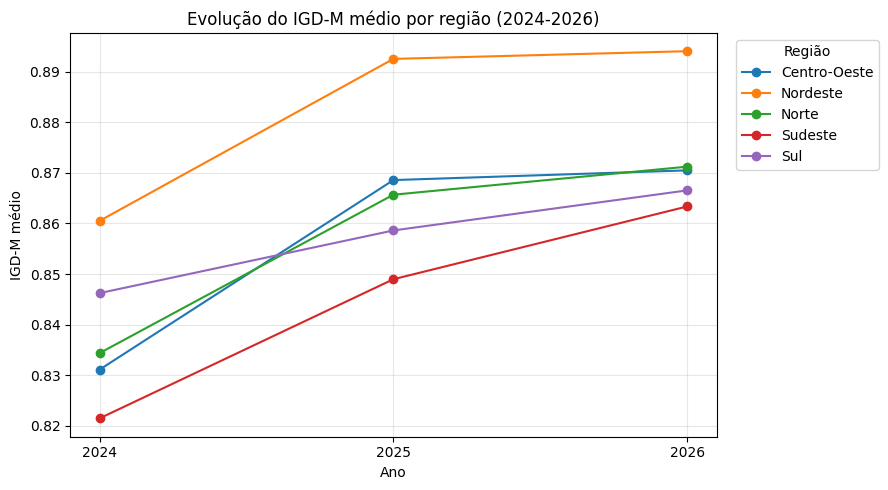

In [10]:
pivot_regiao = regiao_ano.pivot(index="ano", columns="regiao", values="igdm_f")

fig, ax = plt.subplots(figsize=(9, 5))
pivot_regiao.plot(marker="o", ax=ax)
ax.set_title("Evolução do IGD-M médio por região (2024-2026)")
ax.set_xlabel("Ano")
ax.set_ylabel("IGD-M médio")
ax.set_xticks(pivot_regiao.index)
ax.legend(title="Região", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Comparação dos indicadores por região em cada ano

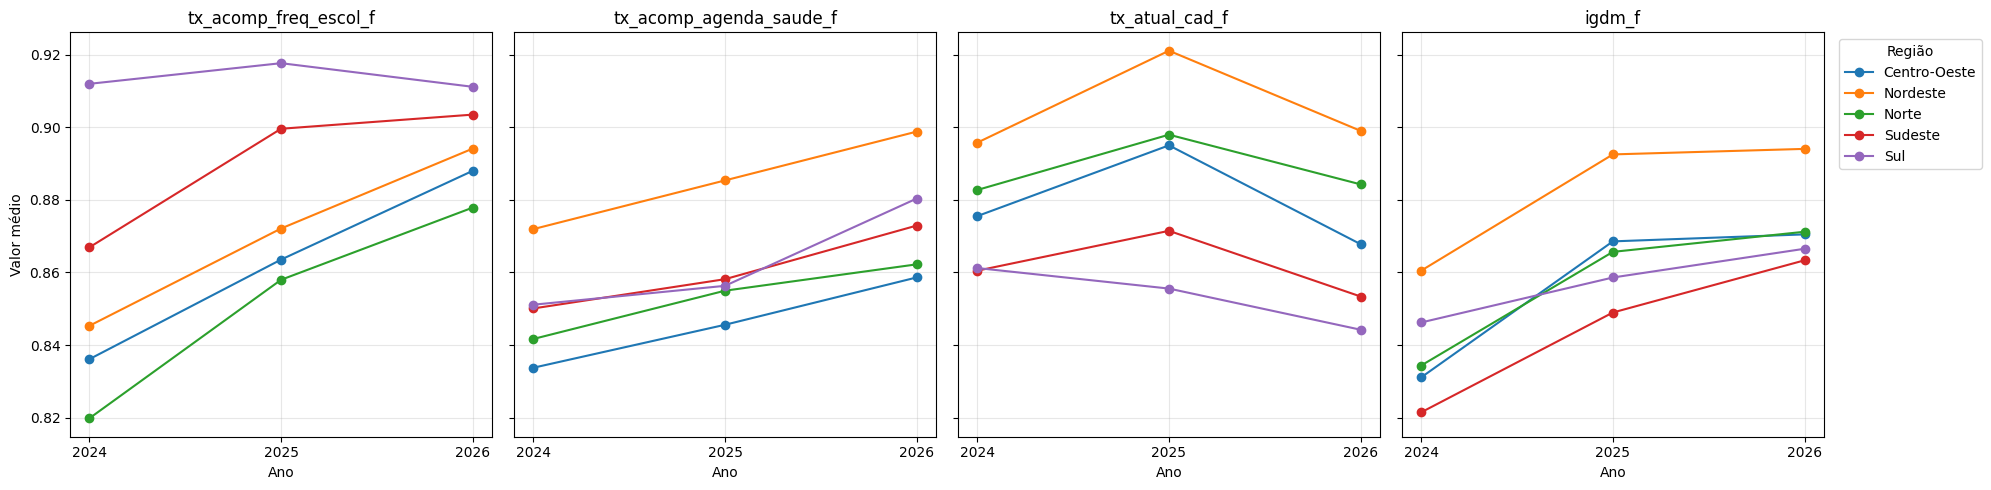

In [11]:
fig, axes = plt.subplots(1, len(indicadores), figsize=(20, 5), sharey=True)

for ax, indicador in zip(axes, indicadores):
    pivot = regiao_ano.pivot(index="ano", columns="regiao", values=indicador)
    pivot.plot(marker="o", ax=ax, legend=False)
    ax.set_title(indicador)
    ax.set_xlabel("Ano")
    ax.set_xticks(pivot.index)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Valor médio")
axes[-1].legend(title="Região", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 6. Ranking de estados por IGD-M em cada ano

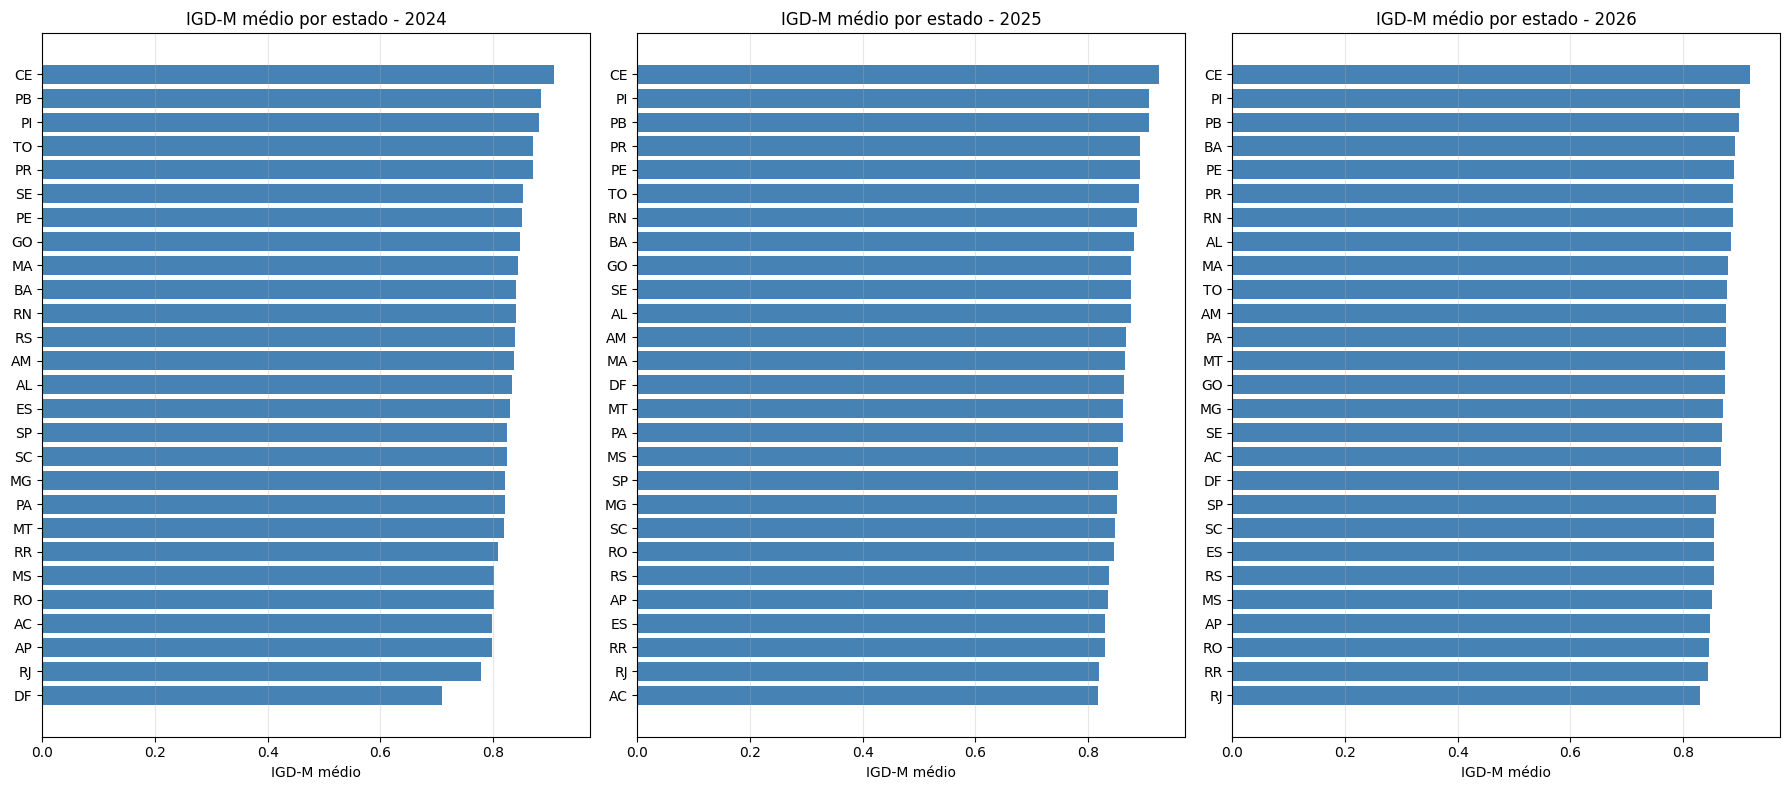

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 8), sharex=True)

for ax, ano in zip(axes, sorted(uf_ano["ano"].unique())):
    dados = uf_ano[uf_ano["ano"] == ano].sort_values("igdm_f")
    ax.barh(dados["uf"], dados["igdm_f"], color="steelblue")
    ax.set_title(f"IGD-M médio por estado - {ano}")
    ax.set_xlabel("IGD-M médio")
    ax.grid(alpha=0.3, axis="x")

plt.tight_layout()
plt.show()

## 7. Variação do IGD-M por estado entre 2024 e 2026

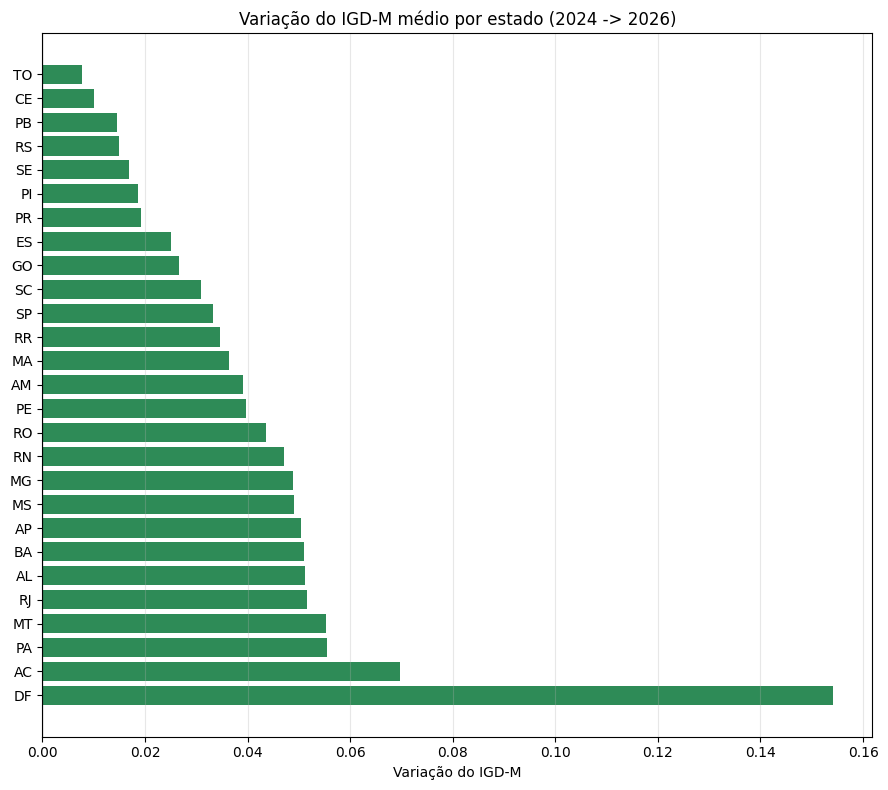

ano,2024,2025,2026,variacao_2024_2026
uf,,,,
DF,0.709208,0.863575,0.863333,0.154125
AC,0.798528,0.818614,0.868182,0.069654
PA,0.820792,0.861643,0.876181,0.055389
MT,0.819570,0.862247,0.874917,0.055348
RJ,0.779081,0.819378,0.830652,0.051571
AL,0.834142,0.876278,0.885343,0.051201
BA,0.841836,0.882697,0.892926,0.051090
AP,0.797671,0.835483,0.848021,0.050349
MS,0.802601,0.854026,0.851667,0.049066


In [13]:
variacao_uf = uf_ano.pivot(index="uf", columns="ano", values="igdm_f")
variacao_uf["variacao_2024_2026"] = variacao_uf[2026] - variacao_uf[2024]
variacao_uf = variacao_uf.sort_values("variacao_2024_2026", ascending=False)

fig, ax = plt.subplots(figsize=(9, 8))
cores = ["seagreen" if v >= 0 else "indianred" for v in variacao_uf["variacao_2024_2026"]]
ax.barh(variacao_uf.index, variacao_uf["variacao_2024_2026"], color=cores)
ax.set_title("Variação do IGD-M médio por estado (2024 -> 2026)")
ax.set_xlabel("Variação do IGD-M")
ax.axvline(0, color="black", linewidth=0.8)
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

variacao_uf

## 6.1 Comparativo por estado: Taxa de Acompanhamento de Frequência Escolar (TAFE)

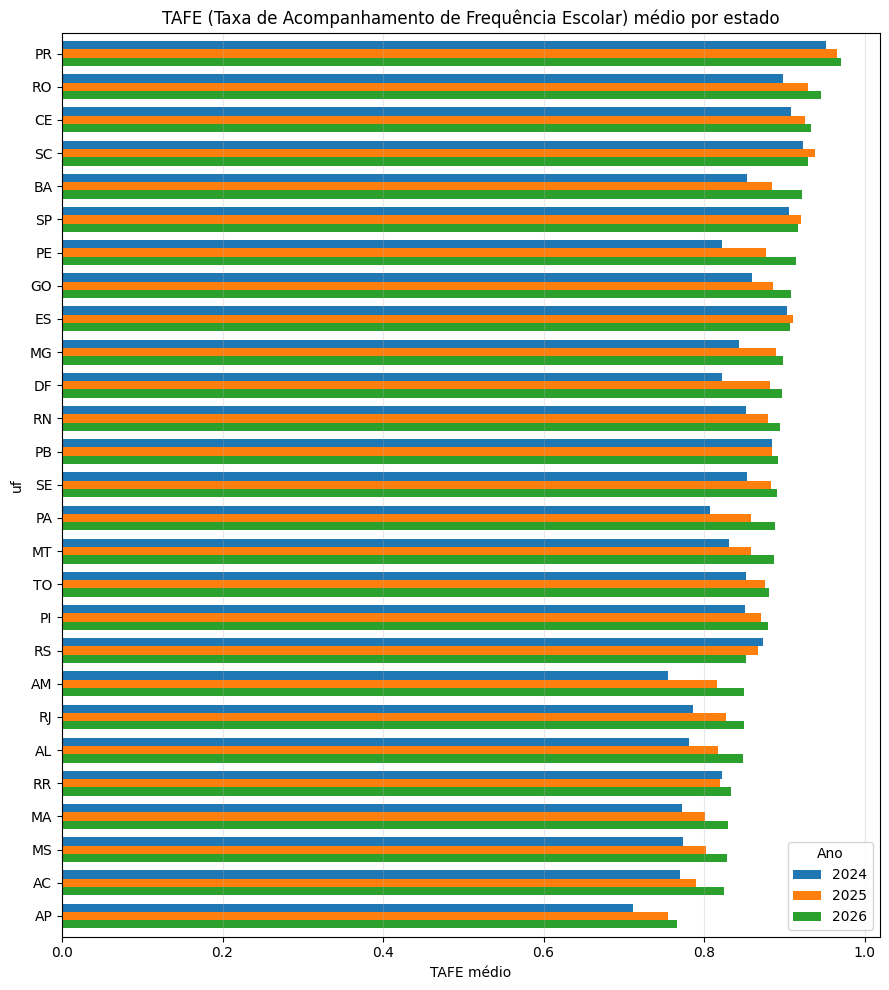

ano,2024,2025,2026,variacao_2024_2026
uf,,,,
PR,0.951472,0.965852,0.970736,0.019264
RO,0.898159,0.929570,0.945481,0.047322
CE,0.908727,0.925387,0.933569,0.024842
SC,0.923771,0.938287,0.929884,0.006113
BA,0.852997,0.885037,0.921599,0.068602
SP,0.905613,0.920791,0.917707,0.012095
PE,0.822050,0.877357,0.914820,0.092770
GO,0.859340,0.886069,0.907818,0.048478
ES,0.903908,0.911362,0.907607,0.003699


In [15]:
pivot_tafe_uf = uf_ano.pivot(index="uf", columns="ano", values="tx_acomp_freq_escol_f")
pivot_tafe_uf["variacao_2024_2026"] = pivot_tafe_uf[2026] - pivot_tafe_uf[2024]
pivot_tafe_uf = pivot_tafe_uf.sort_values(2026, ascending=False)

fig, ax = plt.subplots(figsize=(9, 10))
pivot_tafe_uf[[2024, 2025, 2026]].plot(kind="barh", ax=ax, width=0.75)
ax.set_title("TAFE (Taxa de Acompanhamento de Frequência Escolar) médio por estado")
ax.set_xlabel("TAFE médio")
ax.invert_yaxis()
ax.legend(title="Ano")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

pivot_tafe_uf

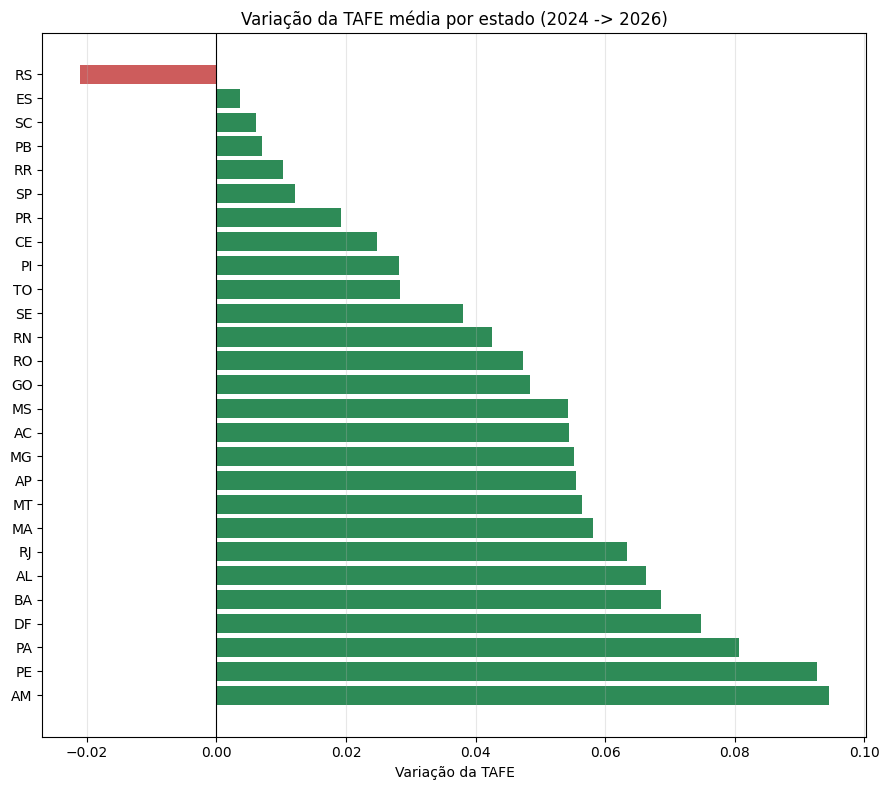

In [16]:
variacao_tafe = pivot_tafe_uf.sort_values("variacao_2024_2026", ascending=False)

fig, ax = plt.subplots(figsize=(9, 8))
cores_tafe = ["seagreen" if v >= 0 else "indianred" for v in variacao_tafe["variacao_2024_2026"]]
ax.barh(variacao_tafe.index, variacao_tafe["variacao_2024_2026"], color=cores_tafe)
ax.set_title("Variação da TAFE média por estado (2024 -> 2026)")
ax.set_xlabel("Variação da TAFE")
ax.axvline(0, color="black", linewidth=0.8)
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

## 8. Tabela resumo final por região

In [14]:
resumo_regiao = regiao_ano.pivot(index="regiao", columns="ano", values=indicadores)
resumo_regiao

tx_acomp_freq_escol_f                      \
ano                           2024      2025      2026   
regiao                                                   
Centro-Oeste              0.836127  0.863553  0.888009   
Nordeste                  0.845313  0.872114  0.894122   
Norte                     0.819841  0.857992  0.877876   
Sudeste                   0.866916  0.899578  0.903473   
Sul                       0.911948  0.917636  0.911129   

             tx_acomp_agenda_saude_f                     tx_atual_cad_f  \
ano                             2024      2025      2026           2024   
regiao                                                                    
Centro-Oeste                0.833769  0.845604  0.858640       0.875521   
Nordeste                    0.871939  0.885356  0.898797       0.895743   
Norte                       0.841691  0.854989  0.862244       0.882717   
Sudeste                     0.850097  0.858159  0.872923       0.860494   
Sul                         0.851125  0.856330  0.880369       0.861230   

                                    igdm_f                      
ano               2025      2026      2024      2025      2026  
regiao                                                          
Centro-Oeste  0.895009  0.867787  0.831118  0.868570  0.870496  
Nordeste      0.921068  0.898992  0.860508  0.892515  0.894037  
Norte         0.897949  0.884259  0.834383  0.865680  0.871222  
Sudeste       0.871473  0.853384  0.821496  0.848983  0.863361  
Sul           0.855573  0.844236  0.846236  0.858622  0.866538